In [1]:
import os
import pandas as pd
import numpy as np

# 1. Check current directory files
all_files = os.listdir('.')
csv_files = [f for f in all_files if f.endswith('.csv')]
print(f"Total CSV files found: {len(csv_files)}")

# 2. Inspect ADANIPORTS.csv as a sample
sample_file = 'ADANIPORTS.csv'

if os.path.exists(sample_file):
    df_sample = pd.read_csv(sample_file)
    print("\n--- SAMPLE FILE (ADANIPORTS.csv) INFO ---")
    print(f"Shape: {df_sample.shape[0]} rows, {df_sample.shape[1]} columns")
    print("\nColumn Names and Data Types:")
    print(df_sample.dtypes)
    print("\nFirst 3 rows:")
    display(df_sample.head(3))
    
    # Check date range
    df_sample['Date'] = pd.to_datetime(df_sample['Date'])
    print(f"\nDate Range: From {df_sample['Date'].min().strftime('%Y-%m-%d')} to {df_sample['Date'].max().strftime('%Y-%m-%d')}")
    
    # Check missing values
    print("\nMissing values per column:")
    print(df_sample.isnull().sum())
else:
    print(f"Error: Could not find {sample_file}. Please check the folder path!")

Total CSV files found: 52

--- SAMPLE FILE (ADANIPORTS.csv) INFO ---
Shape: 3322 rows, 15 columns

Column Names and Data Types:
Date                      str
Symbol                    str
Series                    str
Prev Close            float64
Open                  float64
High                  float64
Low                   float64
Last                  float64
Close                 float64
VWAP                  float64
Volume                  int64
Turnover              float64
Trades                float64
Deliverable Volume      int64
%Deliverble           float64
dtype: object

First 3 rows:


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble
0,2007-11-27,MUNDRAPORT,EQ,440.0,770.0,1050.00,770.0,959.0,962.9,984.72,27294366,2.687719e+15,NaN,9859619,0.3612
1,2007-11-28,MUNDRAPORT,EQ,962.9,984.0,990.00,874.0,885.0,893.9,941.38,4581338,4.312765e+14,NaN,1453278,0.3172
2,2007-11-29,MUNDRAPORT,EQ,893.9,909.0,914.75,841.0,887.0,884.2,888.09,5124121,4.550658e+14,NaN,1069678,0.2088



Date Range: From 2007-11-27 to 2021-04-30

Missing values per column:
Date                    0
Symbol                  0
Series                  0
Prev Close              0
Open                    0
High                    0
Low                     0
Last                    0
Close                   0
VWAP                    0
Volume                  0
Turnover                0
Trades                866
Deliverable Volume      0
%Deliverble             0
dtype: int64


In [2]:
# Step 1.2: Check NIFTY50_all.csv and stock_metadata.csv

# 1. Check stock_metadata.csv
if os.path.exists('stock_metadata.csv'):
    df_meta = pd.read_csv('stock_metadata.csv')
    print("=== STOCK METADATA ===")
    print(f"Shape: {df_meta.shape}")
    print("Columns:", df_meta.columns.tolist())
    display(df_meta.head(5))
else:
    print("stock_metadata.csv not found!")

# 2. Check NIFTY50_all.csv
if os.path.exists('NIFTY50_all.csv'):
    df_all = pd.read_csv('NIFTY50_all.csv')
    print("\n=== NIFTY50_ALL.CSV INFO ===")
    print(f"Total Rows: {len(df_all):,}")
    print(f"Columns: {df_all.columns.tolist()}")
    
    # Check date range
    df_all['Date'] = pd.to_datetime(df_all['Date'])
    print(f"Date Range: {df_all['Date'].min().strftime('%Y-%m-%d')} to {df_all['Date'].max().strftime('%Y-%m-%d')}")
    
    # Unique stocks present
    unique_symbols = df_all['Symbol'].nunique()
    print(f"Unique Symbols: {unique_symbols}")
    print("Sample symbols:", df_all['Symbol'].unique()[:10])
else:
    print("NIFTY50_all.csv not found!")

=== STOCK METADATA ===
Shape: (50, 5)
Columns: ['Company Name', 'Industry', 'Symbol', 'Series', 'ISIN Code']


,Company Name,Industry,Symbol,Series,ISIN Code
0,Adani Ports and Special Economic Zone Ltd.,SERVICES,ADANIPORTS,EQ,INE742F01042
1,Asian Paints Ltd.,CONSUMER GOODS,ASIANPAINT,EQ,INE021A01026
2,Axis Bank Ltd.,FINANCIAL SERVICES,AXISBANK,EQ,INE238A01034
3,Bajaj Auto Ltd.,AUTOMOBILE,BAJAJ-AUTO,EQ,INE917I01010
4,Bajaj Finserv Ltd.,FINANCIAL SERVICES,BAJAJFINSV,EQ,INE918I01018



=== NIFTY50_ALL.CSV INFO ===
Total Rows: 235,192
Columns: ['Date', 'Symbol', 'Series', 'Prev Close', 'Open', 'High', 'Low', 'Last', 'Close', 'VWAP', 'Volume', 'Turnover', 'Trades', 'Deliverable Volume', '%Deliverble']
Date Range: 2000-01-03 to 2021-04-30
Unique Symbols: 65
Sample symbols: <ArrowStringArray>
['MUNDRAPORT', 'ADANIPORTS', 'ASIANPAINT',    'UTIBANK',   'AXISBANK',
 'BAJAJ-AUTO', 'BAJAJFINSV', 'BAJAUTOFIN', 'BAJFINANCE',     'BHARTI']
Length: 10, dtype: str


In [3]:
# Phase 2: Data Cleaning, Standardization & Feature Merging

# 1. Load data
df = pd.read_csv('NIFTY50_all.csv')
meta = pd.read_csv('stock_metadata.csv')

# 2. Filter Series to 'EQ' only (Equity trades)
print(f"Rows before Series filter: {len(df):,}")
df = df[df['Series'] == 'EQ'].copy()
print(f"Rows after 'EQ' filter: {len(df):,}")

# 3. Standardize historical ticker symbols to current names
symbol_mapping = {
    'MUNDRAPORT': 'ADANIPORTS',
    'UTIBANK': 'AXISBANK',
    'BAJAUTOFIN': 'BAJFINANCE',
    'BHARTI': 'BHARTIARTL',
    'HEROHONDA': 'HEROMOTOCO',
    'HINDLEVER': 'HINDUNILVR',
    'INFOSYSTCH': 'INFY',
    'KOTAKMAH': 'KOTAKBANK',
    'SESAGOA': 'VEDL',
    'SSLT': 'VEDL',
    'TELCO': 'TATAMOTORS',
    'TISCO': 'TATASTEEL',
    'UNIPHOS': 'UPL'
}

df['Symbol'] = df['Symbol'].replace(symbol_mapping)

# 4. Merge Industry from metadata
meta_clean = meta[['Symbol', 'Industry', 'Company Name']].drop_duplicates()
df = df.merge(meta_clean, on='Symbol', how='left')

# Fill any unmapped industry as 'Other'
df['Industry'] = df['Industry'].fillna('Other')

# 5. Convert Date to datetime and sort chronologically
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(by=['Symbol', 'Date']).reset_index(drop=True)

# 6. Check for duplicate records (same symbol on the same date)
duplicates = df.duplicated(subset=['Symbol', 'Date']).sum()
print(f"Duplicate symbol-date pairs found: {duplicates}")
if duplicates > 0:
    df = df.drop_duplicates(subset=['Symbol', 'Date'], keep='last').reset_index(drop=True)

# 7. Check null values across columns
print("\n--- Missing Values in Cleaned Dataset ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 8. Summary of clean data
print(f"\nFinal Cleaned Rows: {len(df):,}")
print(f"Cleaned Unique Symbols: {df['Symbol'].nunique()}")
print(f"Industries Count: {df['Industry'].nunique()}")
print(f"Date Range: {df['Date'].min().date()} to {df['Date'].max().date()}")

display(df[['Date', 'Symbol', 'Company Name', 'Industry', 'Close', 'Volume']].head(5))

Rows before Series filter: 235,192
Rows after 'EQ' filter: 235,192
Duplicate symbol-date pairs found: 0

--- Missing Values in Cleaned Dataset ---
Trades                114848
Deliverable Volume     16077
%Deliverble            16077
Company Name            3838
dtype: int64

Final Cleaned Rows: 235,192
Cleaned Unique Symbols: 52
Industries Count: 14
Date Range: 2000-01-03 to 2021-04-30


,Date,Symbol,Company Name,Industry,Close,Volume
0,2007-11-27,ADANIPORTS,Adani Ports and Special Economic Zone Ltd.,SERVICES,962.90,27294366
1,2007-11-28,ADANIPORTS,Adani Ports and Special Economic Zone Ltd.,SERVICES,893.90,4581338
2,2007-11-29,ADANIPORTS,Adani Ports and Special Economic Zone Ltd.,SERVICES,884.20,5124121
3,2007-11-30,ADANIPORTS,Adani Ports and Special Economic Zone Ltd.,SERVICES,921.55,4609762
4,2007-12-03,ADANIPORTS,Adani Ports and Special Economic Zone Ltd.,SERVICES,969.30,2977470


Decade Data Shape: (125342, 17)

=== CORRELATION WITH 20-DAY ROLLING VOLATILITY ===
Rolling_Vol_20D    1.000000
Intraday_Range     0.311350
Abs_Return         0.303074
Trades             0.250493
Turnover_Cr        0.153096
Volume_Surge       0.060809
%Deliverble       -0.251447
Name: Rolling_Vol_20D, dtype: float64


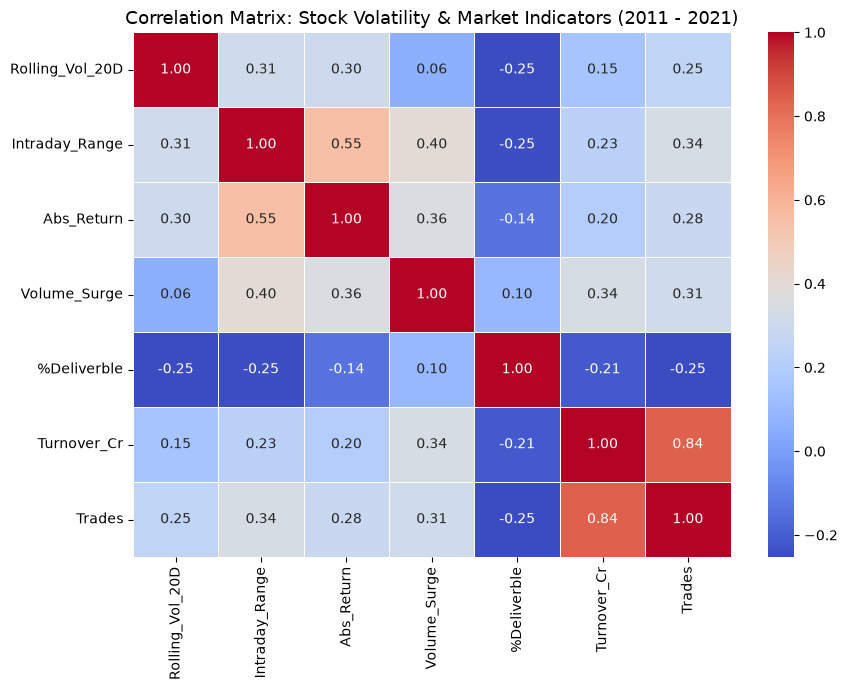

In [5]:
# Phase 3: Volatility and Indicator Analysis (2011 - 2021)
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter for the last decade (2011 to 2021)
df_decade = df[(df['Date'] >= '2011-01-01') & (df['Date'] <= '2021-04-30')].copy()
print(f"Decade Data Shape: {df_decade.shape}")

# 2. Compute Financial Indicators per stock
df_decade = df_decade.sort_values(by=['Symbol', 'Date']).reset_index(drop=True)

# Daily Return
df_decade['Daily_Return'] = df_decade.groupby('Symbol')['Close'].pct_change()

# Absolute Daily Return (direct proxy for daily price unpredictability)
df_decade['Abs_Return'] = df_decade['Daily_Return'].abs()

# Intraday Range Spread (High - Low) / Low
df_decade['Intraday_Range'] = (df_decade['High'] - df_decade['Low']) / df_decade['Low']

# 20-Day Rolling Annualized Volatility (252 trading days/year)
df_decade['Rolling_Vol_20D'] = (
    df_decade.groupby('Symbol')['Daily_Return']
    .rolling(window=20)
    .std()
    .reset_index(level=0, drop=True)
) * np.sqrt(252)

# Volume Spike Ratio (Today's Volume / 20-Day Moving Average Volume)
df_decade['Vol_MA_20'] = df_decade.groupby('Symbol')['Volume'].rolling(20).mean().reset_index(level=0, drop=True)
df_decade['Volume_Surge'] = df_decade['Volume'] / df_decade['Vol_MA_20']

# Turnover in Crores (1 Crore = 10,000,000 INR)
df_decade['Turnover_Cr'] = df_decade['Turnover'] / 1e7

# 3. Select key numerical indicators for correlation with Volatility
indicators = [
    'Rolling_Vol_20D', 
    'Intraday_Range', 
    'Abs_Return', 
    'Volume_Surge', 
    '%Deliverble', 
    'Turnover_Cr',
    'Trades'
]

# Drop NaNs that occur naturally from 20-day rolling calculations
df_corr = df_decade[indicators].dropna()

# 4. Correlation Matrix
corr_matrix = df_corr.corr()

print("\n=== CORRELATION WITH 20-DAY ROLLING VOLATILITY ===")
print(corr_matrix['Rolling_Vol_20D'].sort_values(ascending=False))

# 5. Plot Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix: Stock Volatility & Market Indicators (2011 - 2021)", fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
# Phase 4: Stock Performance Evaluation & Selection (2011 - 2021)

risk_free_rate = 0.06  # 6% Risk-Free Rate (standard Indian 10-Yr G-Sec)

stock_perf = []

# Group by each stock
for sym, group in df_decade.groupby('Symbol'):
    group = group.sort_values('Date').reset_index(drop=True)
    
    # Needs sufficient data history (at least 5 years / 1200 trading days)
    if len(group) < 1200:
        continue
        
    start_price = group['Close'].iloc[0]
    end_price = group['Close'].iloc[-1]
    trading_days = len(group)
    years = trading_days / 252.0
    
    # 1. CAGR
    cagr = (end_price / start_price) ** (1.0 / years) - 1.0
    
    # 2. Daily returns & Annualized Volatility
    returns = group['Close'].pct_change().dropna()
    annual_vol = returns.std() * np.sqrt(252)
    
    # 3. Sharpe Ratio
    sharpe = (cagr - risk_free_rate) / annual_vol if annual_vol > 0 else 0
    
    # 4. Maximum Drawdown
    cum_returns = (1 + returns).cumprod()
    cum_max = cum_returns.cummax()
    drawdown = (cum_returns - cum_max) / cum_max
    max_drawdown = drawdown.min()
    
    # 5. Average Deliverable % and Industry
    avg_deliv = group['%Deliverble'].mean()
    ind = group['Industry'].iloc[0] if 'Industry' in group.columns else 'Unknown'
    
    stock_perf.append({
        'Symbol': sym,
        'Industry': ind,
        'CAGR (%)': round(cagr * 100, 2),
        'Annual_Vol (%)': round(annual_vol * 100, 2),
        'Sharpe_Ratio': round(sharpe, 2),
        'Max_Drawdown (%)': round(max_drawdown * 100, 2),
        'Avg_Delivery (%)': round(avg_deliv * 100, 2) if pd.notnull(avg_deliv) else 0
    })

# Convert to DataFrame
df_perf = pd.DataFrame(stock_perf)

# Sort by Sharpe Ratio
df_perf_sorted = df_perf.sort_values(by='Sharpe_Ratio', ascending=False).reset_index(drop=True)

print("=== TOP 10 BEST PERFORMING STOCKS BY SHARPE RATIO (2011 - 2021) ===")
display(df_perf_sorted.head(10))

print("\n=== BOTTOM 5 WORST PERFORMING STOCKS ===")
display(df_perf_sorted.tail(5))

=== TOP 10 BEST PERFORMING STOCKS BY SHARPE RATIO (2011 - 2021) ===


,Symbol,Industry,CAGR (%),Annual_Vol (%),Sharpe_Ratio,Max_Drawdown (%),Avg_Delivery (%)
0,BAJAJFINSV,FINANCIAL SERVICES,36.46,35.57,0.86,-58.59,44.19
1,SHREECEM,CEMENT & CEMENT PRODUCTS,29.49,29.41,0.80,-36.90,62.71
2,HINDUNILVR,CONSUMER GOODS,21.98,24.30,0.66,-25.12,61.66
3,BRITANNIA,CONSUMER GOODS,23.36,30.88,0.56,-69.02,58.39
4,ULTRACEMCO,CEMENT & CEMENT PRODUCTS,18.85,28.18,0.46,-37.66,56.99
5,NESTLEIND,CONSUMER GOODS,15.33,24.07,0.39,-32.40,65.46
6,BAJFINANCE,FINANCIAL SERVICES,22.33,47.09,0.35,-93.28,51.08
7,MARUTI,AUTOMOBILE,16.04,29.85,0.34,-59.20,40.80
8,ADANIPORTS,SERVICES,17.26,38.42,0.29,-53.69,44.91
9,KOTAKBANK,FINANCIAL SERVICES,14.13,32.97,0.25,-58.45,53.80



=== BOTTOM 5 WORST PERFORMING STOCKS ===


,Symbol,Industry,CAGR (%),Annual_Vol (%),Sharpe_Ratio,Max_Drawdown (%),Avg_Delivery (%)
44,COALINDIA,METALS,-8.21,29.86,-0.48,-75.07,55.11
45,IOC,ENERGY,-12.53,38.90,-0.48,-89.00,46.62
46,GAIL,ENERGY,-12.22,37.12,-0.49,-86.88,53.45
47,SBIN,FINANCIAL SERVICES,-18.51,45.42,-0.54,-94.88,30.81
48,ONGC,ENERGY,-21.68,42.38,-0.65,-95.34,53.88


Selected Portfolio Equities: ['BAJAJFINSV', 'SHREECEM', 'HINDUNILVR', 'MARUTI', 'ADANIPORTS']

=== PORTFOLIO VS BENCHMARK PERFORMANCE (2011 - 2021) ===


,Metric,Our Portfolio,Nifty 50 Benchmark
0,CAGR (%),27.67%,11.25%
1,Annualized Volatility (%),20.38%,17.50%
2,Sharpe Ratio,1.06,0.30
3,Max Drawdown (%),-37.87%,-42.49%
4,"Final Value of ₹100,000","₹1,202,761.16","₹294,472.03"


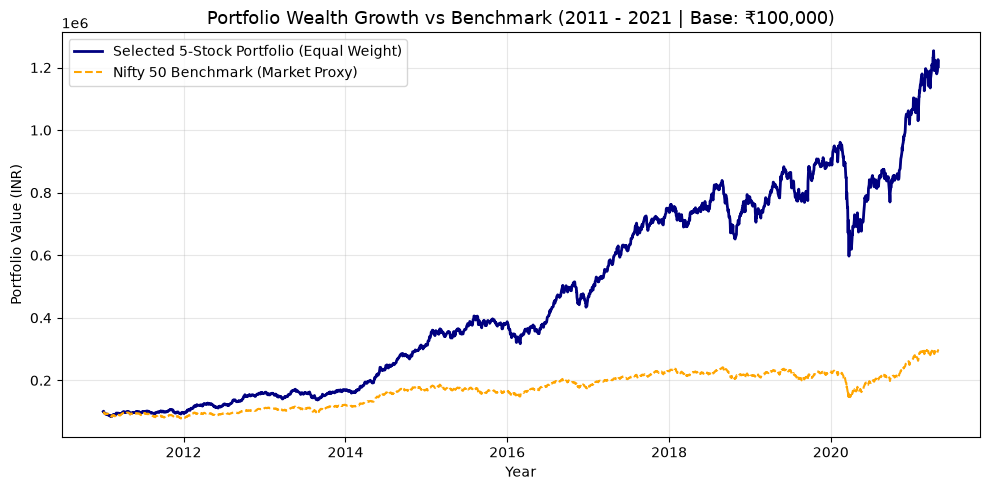

In [7]:
# Phase 4 (Part 2): Portfolio Construction & Backtesting vs Benchmark

# 1. Selected Top 5 diversified equities
selected_stocks = ['BAJAJFINSV', 'SHREECEM', 'HINDUNILVR', 'MARUTI', 'ADANIPORTS']
print("Selected Portfolio Equities:", selected_stocks)

# 2. Pivot closing prices for the decade: columns = symbols, rows = dates
price_matrix = df_decade.pivot(index='Date', columns='Symbol', values='Close')

# Calculate daily returns for all stocks
returns_matrix = price_matrix.pct_change()

# 3. Construct Portfolio (Equal Weight = 20% each)
portfolio_returns = returns_matrix[selected_stocks].mean(axis=1)

# 4. Construct Benchmark (Equal weight of all available Nifty 50 stocks)
benchmark_returns = returns_matrix.mean(axis=1)

# 5. Calculate Cumulative Wealth Growth (starting with ₹100,000 capital)
initial_capital = 100000
portfolio_wealth = (1 + portfolio_returns).cumprod() * initial_capital
benchmark_wealth = (1 + benchmark_returns).cumprod() * initial_capital

# 6. Overall Performance Metrics
def get_metrics(ret_series, wealth_series):
    total_days = len(ret_series.dropna())
    years = total_days / 252.0
    cagr = ((wealth_series.iloc[-1] / wealth_series.iloc[0]) ** (1.0 / years) - 1.0) * 100
    ann_vol = ret_series.std() * np.sqrt(252) * 100
    sharpe = (cagr - 6.0) / ann_vol  # 6% risk-free
    drawdown = (wealth_series - wealth_series.cummax()) / wealth_series.cummax()
    max_dd = drawdown.min() * 100
    return cagr, ann_vol, sharpe, max_dd

port_cagr, port_vol, port_sharpe, port_mdd = get_metrics(portfolio_returns, portfolio_wealth.dropna())
bm_cagr, bm_vol, bm_sharpe, bm_mdd = get_metrics(benchmark_returns, benchmark_wealth.dropna())

# 7. Print Comparison Table
comp_df = pd.DataFrame({
    'Metric': ['CAGR (%)', 'Annualized Volatility (%)', 'Sharpe Ratio', 'Max Drawdown (%)', 'Final Value of ₹100,000'],
    'Our Portfolio': [f"{port_cagr:.2f}%", f"{port_vol:.2f}%", f"{port_sharpe:.2f}", f"{port_mdd:.2f}%", f"₹{portfolio_wealth.iloc[-1]:,.2f}"],
    'Nifty 50 Benchmark': [f"{bm_cagr:.2f}%", f"{bm_vol:.2f}%", f"{bm_sharpe:.2f}", f"{bm_mdd:.2f}%", f"₹{benchmark_wealth.iloc[-1]:,.2f}"]
})

print("\n=== PORTFOLIO VS BENCHMARK PERFORMANCE (2011 - 2021) ===")
display(comp_df)

# 8. Plot Wealth Accumulation Curve
plt.figure(figsize=(10, 5))
plt.plot(portfolio_wealth.index, portfolio_wealth, label='Selected 5-Stock Portfolio (Equal Weight)', color='navy', linewidth=2)
plt.plot(benchmark_wealth.index, benchmark_wealth, label='Nifty 50 Benchmark (Market Proxy)', color='orange', linestyle='--', linewidth=1.5)
plt.title("Portfolio Wealth Growth vs Benchmark (2011 - 2021 | Base: ₹100,000)", fontsize=13)
plt.ylabel("Portfolio Value (INR)")
plt.xlabel("Year")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Training observations: 1932 (From 2011-03-15 to 2018-12-31)
Testing observations:  576  (From 2019-01-01 to 2021-04-29)

=== MODEL PERFORMANCE ON UNSEEN TEST DATA (2019 - 2021) ===
Accuracy Score: 46.53%
ROC-AUC Score:  0.458

Classification Report:
               precision    recall  f1-score   support

           0       0.45      0.37      0.40       284
           1       0.48      0.56      0.52       292

    accuracy                           0.47       576
   macro avg       0.46      0.46      0.46       576
weighted avg       0.46      0.47      0.46       576

=== FEATURE IMPORTANCES ===


,Feature,Importance
7,%Deliverble,0.168092
0,Return_1D,0.147800
5,Intraday_Range,0.121134
4,RSI_14,0.116657
2,Return_5D,0.116293
1,Return_2D,0.113456
3,SMA_Ratio,0.110100
6,Volume_Surge,0.106468


C:\Users\Uma sankar rao\AppData\Local\Temp\ipykernel_10924\3707736154.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x='Importance', y='Feature', palette='viridis')


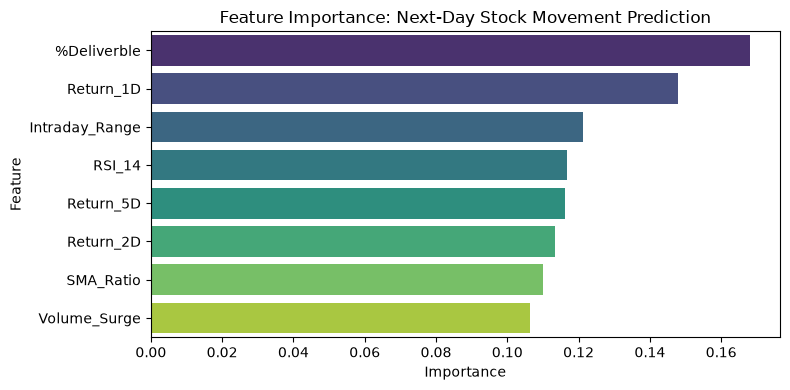

In [8]:
# Phase 5: Feature Engineering & Time-Series Classification (Flagship Stock: BAJAJFINSV)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

# 1. Isolate the flagship asset (BAJAJFINSV)
df_ml = df_decade[df_decade['Symbol'] == 'BAJAJFINSV'].sort_values('Date').copy().reset_index(drop=True)

# 2. Feature Engineering
# Return Lags
df_ml['Return_1D'] = df_ml['Close'].pct_change(1)
df_ml['Return_2D'] = df_ml['Close'].pct_change(2)
df_ml['Return_5D'] = df_ml['Close'].pct_change(5)

# Moving Average Trend
df_ml['SMA_10'] = df_ml['Close'].rolling(window=10).mean()
df_ml['SMA_50'] = df_ml['Close'].rolling(window=50).mean()
df_ml['SMA_Ratio'] = df_ml['SMA_10'] / df_ml['SMA_50']

# RSI (Relative Strength Index - 14 Days)
delta = df_ml['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / (loss + 1e-9)
df_ml['RSI_14'] = 100 - (100 / (1 + rs))

# Volatility & Volume Indicators
df_ml['Intraday_Range'] = (df_ml['High'] - df_ml['Low']) / df_ml['Low']
df_ml['Vol_MA_20'] = df_ml['Volume'].rolling(20).mean()
df_ml['Volume_Surge'] = df_ml['Volume'] / (df_ml['Vol_MA_20'] + 1e-9)

# 3. Create Target Variable (Next-Day Direction: 1 = UP, 0 = DOWN)
df_ml['Target_Tomorrow'] = (df_ml['Close'].shift(-1) > df_ml['Close']).astype(int)

# 4. Clean NaNs caused by rolling windows and the final shifted target row
features = ['Return_1D', 'Return_2D', 'Return_5D', 'SMA_Ratio', 'RSI_14', 'Intraday_Range', 'Volume_Surge', '%Deliverble']
df_ml_clean = df_ml.dropna(subset=features).iloc[:-1].copy()

# 5. Chronological Train-Test Split (Train: 2011 to 2018 | Test: 2019 to 2021)
train_mask = df_ml_clean['Date'] < '2019-01-01'
test_mask = df_ml_clean['Date'] >= '2019-01-01'

X_train = df_ml_clean.loc[train_mask, features]
y_train = df_ml_clean.loc[train_mask, 'Target_Tomorrow']

X_test = df_ml_clean.loc[test_mask, features]
y_test = df_ml_clean.loc[test_mask, 'Target_Tomorrow']

print(f"Training observations: {len(X_train)} (From {df_ml_clean.loc[train_mask, 'Date'].min().date()} to {df_ml_clean.loc[train_mask, 'Date'].max().date()})")
print(f"Testing observations:  {len(X_test)}  (From {df_ml_clean.loc[test_mask, 'Date'].min().date()} to {df_ml_clean.loc[test_mask, 'Date'].max().date()})")

# 6. Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train, y_train)

# 7. Model Predictions & Evaluation
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred_proba)

print("\n=== MODEL PERFORMANCE ON UNSEEN TEST DATA (2019 - 2021) ===")
print(f"Accuracy Score: {acc * 100:.2f}%")
print(f"ROC-AUC Score:  {auc:.3f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 8. Feature Importance Analysis
fi_df = pd.DataFrame({'Feature': features, 'Importance': rf_model.feature_importances_}).sort_values('Importance', ascending=False)
print("=== FEATURE IMPORTANCES ===")
display(fi_df)

# Plot Feature Importance
plt.figure(figsize=(8, 4))
sns.barplot(data=fi_df, x='Importance', y='Feature', palette='viridis')
plt.title("Feature Importance: Next-Day Stock Movement Prediction", fontsize=12)
plt.tight_layout()
plt.show()

=== WEEKLY (5-DAY) TREND MODEL PERFORMANCE (2019 - 2021) ===
Weekly Direction Accuracy: 54.72%

Classification Report:
               precision    recall  f1-score   support

           0       0.45      0.07      0.12       255
           1       0.55      0.93      0.70       317

    accuracy                           0.55       572
   macro avg       0.50      0.50      0.41       572
weighted avg       0.51      0.55      0.44       572



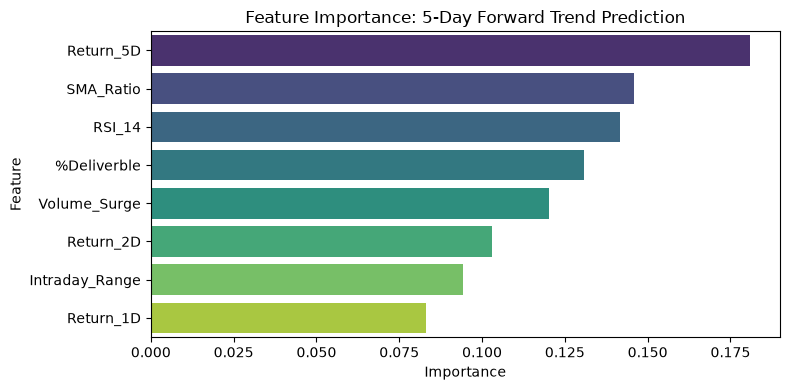

In [9]:
# Phase 5 (Refined): Multi-Day (Weekly) Momentum Prediction + Clean Visuals

# 1. Target: Will the stock be higher 5 trading days from now? (Weekly Trend)
df_ml['Target_5D'] = (df_ml['Close'].shift(-5) > df_ml['Close']).astype(int)

# 2. Clean subset
df_ml_5d = df_ml.dropna(subset=features + ['Target_5D']).iloc[:-5].copy()

# 3. Train-Test Split (Train: 2011-2018 | Test: 2019-2021)
train_mask = df_ml_5d['Date'] < '2019-01-01'
test_mask = df_ml_5d['Date'] >= '2019-01-01'

X_train_5d = df_ml_5d.loc[train_mask, features]
y_train_5d = df_ml_5d.loc[train_mask, 'Target_5D']

X_test_5d = df_ml_5d.loc[test_mask, features]
y_test_5d = df_ml_5d.loc[test_mask, 'Target_5D']

# 4. Train Model
rf_5d = RandomForestClassifier(n_estimators=100, max_depth=4, min_samples_leaf=10, random_state=42)
rf_5d.fit(X_train_5d, y_train_5d)

# 5. Evaluate
y_pred_5d = rf_5d.predict(X_test_5d)
acc_5d = accuracy_score(y_test_5d, y_pred_5d)

print(f"=== WEEKLY (5-DAY) TREND MODEL PERFORMANCE (2019 - 2021) ===")
print(f"Weekly Direction Accuracy: {acc_5d * 100:.2f}%")
print("\nClassification Report:\n", classification_report(y_test_5d, y_pred_5d))

# 6. Clean Plot without any Seaborn FutureWarnings
fi_df_5d = pd.DataFrame({'Feature': features, 'Importance': rf_5d.feature_importances_}).sort_values('Importance', ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(data=fi_df_5d, x='Importance', y='Feature', hue='Feature', legend=False, palette='viridis')
plt.title("Feature Importance: 5-Day Forward Trend Prediction", fontsize=12)
plt.tight_layout()
plt.show()

In [10]:
# Save clean data for the interactive dashboard
import os

# 1. Save portfolio performance summary
comp_df.to_csv('portfolio_summary.csv', index=False)

# 2. Save top 10 stocks metrics
df_perf_sorted.to_csv('stock_metrics.csv', index=False)

# 3. Save selected decade data with essential columns for faster dashboard rendering
dashboard_stocks = ['BAJAJFINSV', 'SHREECEM', 'HINDUNILVR', 'MARUTI', 'ADANIPORTS', 'RELIANCE', 'TCS', 'INFY', 'HDFCBANK']
df_dash = df_decade[df_decade['Symbol'].isin(dashboard_stocks)][[
    'Date', 'Symbol', 'Company Name', 'Industry', 'Close', 'Open', 'High', 'Low', 'Volume', '%Deliverble', 'Rolling_Vol_20D'
]].copy()

df_dash.to_csv('dashboard_data.csv', index=False)
print("Dashboard data files successfully saved:")
print("- portfolio_summary.csv")
print("- stock_metrics.csv")
print("- dashboard_data.csv")

Dashboard data files successfully saved:
- portfolio_summary.csv
- stock_metrics.csv
- dashboard_data.csv


In [11]:
# Export clean tables specifically designed for Power BI Dashboard

# 1. Stock Ranking & Performance Metrics Table
df_perf_sorted.to_csv('PowerBI_Stock_Metrics.csv', index=False)

# 2. Portfolio vs Benchmark Daily Wealth Growth Table
df_wealth_tracker = pd.DataFrame({
    'Date': portfolio_wealth.index,
    'Our_Portfolio_Wealth': portfolio_wealth.values,
    'Benchmark_Wealth': benchmark_wealth.values
})
df_wealth_tracker.to_csv('PowerBI_Portfolio_Vs_Benchmark.csv', index=False)

# 3. Comprehensive Stock Time-Series for Visuals & Slicers
df_powerbi_timeseries = df_decade[[
    'Date', 'Symbol', 'Company Name', 'Industry', 'Close', 'Open', 'High', 'Low', 
    'Volume', 'Turnover_Cr', '%Deliverble', 'Rolling_Vol_20D', 'Intraday_Range'
]].copy()

df_powerbi_timeseries.to_csv('PowerBI_Stock_Analysis.csv', index=False)

print("SUCCESS! 3 files generated for Power BI:")
print("1. PowerBI_Stock_Metrics.csv")
print("2. PowerBI_Portfolio_Vs_Benchmark.csv")
print("3. PowerBI_Stock_Analysis.csv")

SUCCESS! 3 files generated for Power BI:
1. PowerBI_Stock_Metrics.csv
2. PowerBI_Portfolio_Vs_Benchmark.csv
3. PowerBI_Stock_Analysis.csv


In [12]:
# Full 2 Decades (2000 - 2021) Portfolio & Benchmark Analysis

# 1. Filter the entire dataset (2000 to 2021)
df_2decades = df[(df['Date'] >= '2000-01-01') & (df['Date'] <= '2021-04-30')].copy()

# 2. Pivot closing prices across the entire 2000-2021 period
price_matrix_20y = df_2decades.pivot(index='Date', columns='Symbol', values='Close')
returns_matrix_20y = price_matrix_20y.pct_change()

# 3. Use top long-standing market leaders active across the 2 decades
# (HINDUNILVR, RELIANCE, HDFCBANK, INFOSYS/INFY, TATASTEEL)
core_20y_stocks = ['HINDUNILVR', 'RELIANCE', 'HDFCBANK', 'INFY', 'TATASTEEL']

# Portfolio 20-year returns (Equal weight of the 5 multi-decade pillars)
portfolio_returns_20y = returns_matrix_20y[core_20y_stocks].mean(axis=1)

# Broad market 20-year benchmark
benchmark_returns_20y = returns_matrix_20y.mean(axis=1)

# 4. Wealth growth of ₹100,000 from 2000 to 2021
initial_capital = 100000
wealth_20y_port = (1 + portfolio_returns_20y.fillna(0)).cumprod() * initial_capital
wealth_20y_bench = (1 + benchmark_returns_20y.fillna(0)).cumprod() * initial_capital

# 5. Export 20-Year file for Power BI
df_20y_export = pd.DataFrame({
    'Date': wealth_20y_port.index,
    'Our_20Y_Portfolio_Wealth': wealth_20y_port.values,
    'Benchmark_20Y_Wealth': wealth_20y_bench.values
})
df_20y_export.to_csv('PowerBI_2Decades_Wealth.csv', index=False)

# 6. Also compute 20-Year metrics per stock
stock_20y_perf = []
for sym in df_2decades['Symbol'].unique():
    grp = df_2decades[df_2decades['Symbol'] == sym].sort_values('Date')
    if len(grp) < 1500:
        continue
    p_start = grp['Close'].iloc[0]
    p_end = grp['Close'].iloc[-1]
    n_years = len(grp) / 252.0
    cagr_20y = ((p_end / p_start) ** (1.0 / n_years) - 1.0) * 100
    ret_20y = grp['Close'].pct_change().dropna()
    vol_20y = ret_20y.std() * np.sqrt(252) * 100
    sharpe_20y = (cagr_20y - 6.0) / vol_20y if vol_20y > 0 else 0
    
    cum = (1 + ret_20y).cumprod()
    mdd_20y = ((cum - cum.cummax()) / cum.cummax()).min() * 100
    
    ind = grp['Industry'].iloc[0] if 'Industry' in grp.columns else 'Other'
    stock_20y_perf.append({
        'Symbol': sym,
        'Industry': ind,
        'CAGR_20Y (%)': round(cagr_20y, 2),
        'Annual_Vol_20Y (%)': round(vol_20y, 2),
        'Sharpe_20Y': round(sharpe_20y, 2),
        'Max_Drawdown_20Y (%)': round(mdd_20y, 2)
    })

df_20y_metrics = pd.DataFrame(stock_20y_perf).sort_values(by='Sharpe_20Y', ascending=False)
df_20y_metrics.to_csv('PowerBI_2Decades_Metrics.csv', index=False)

print("SUCCESS! Created 20-year (2 Decades: 2000-2021) files:")
print("1. PowerBI_2Decades_Wealth.csv")
print("2. PowerBI_2Decades_Metrics.csv")

print(f"\n20-Year Growth of ₹100,000 (2000 to 2021):")
print(f"5-Pillar Portfolio ended at: ₹{wealth_20y_port.iloc[-1]:,.2f}")
print(f"Benchmark ended at: ₹{wealth_20y_bench.iloc[-1]:,.2f}")

SUCCESS! Created 20-year (2 Decades: 2000-2021) files:
1. PowerBI_2Decades_Wealth.csv
2. PowerBI_2Decades_Metrics.csv

20-Year Growth of ₹100,000 (2000 to 2021):
5-Pillar Portfolio ended at: ₹967,361.94
Benchmark ended at: ₹2,489,256.88


In [13]:
# Task 4 Upgrade: Multi-Model Benchmark & Evaluation (Logistic Regression vs. Random Forest)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

# 1. Setup Models
models = {
    'Logistic Regression (Baseline)': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(random_state=42))
    ]),
    'Random Forest (Non-Linear Ensemble)': RandomForestClassifier(
        n_estimators=100, max_depth=4, min_samples_leaf=10, random_state=42
    )
}

# 2. Train and Evaluate Both Models
results = []
for name, model in models.items():
    model.fit(X_train_5d, y_train_5d)
    preds = model.predict(X_test_5d)
    probs = model.predict_proba(X_test_5d)[:, 1]
    
    results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test_5d, preds) * 100, 2),
        'Precision (%)': round(precision_score(y_test_5d, preds) * 100, 2),
        'Recall (%)': round(recall_score(y_test_5d, preds) * 100, 2),
        'ROC-AUC': round(roc_auc_score(y_test_5d, probs), 3)
    })

# 3. Display Side-by-Side Comparison
df_model_comp = pd.DataFrame(results)
print("=== CAPSTONE MACHINE LEARNING BENCHMARK MATRIX ===")
display(df_model_comp)

=== CAPSTONE MACHINE LEARNING BENCHMARK MATRIX ===


,Model,Accuracy (%),Precision (%),Recall (%),ROC-AUC
0,Logistic Regression (Baseline),53.50,56.00,75.08,0.514
1,Random Forest (Non-Linear Ensemble),54.72,55.43,93.38,0.526
